# Results

Every figure and table of the results section, in the order the paper
presents them.

In [9]:
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from utils.results import (head_to_head, load_results, select,
                           simplify_labels, summary_table)
from utils.plots import pairwise_scatter, performance_profile

warnings.simplefilter('always', UserWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
plt.rcParams['figure.dpi'] = 110

RESULTS_CSV   = 'aws.csv'                  # run results
ROOT_GAPS_CSV = 'relaxation_gaps_all.csv'  # continuous-relaxation gaps

FIGURE_DIR    = 'Results/figures'
SAVE_FIGURES  = False     # write the figures under FIGURE_DIR
PRINT_LATEX   = True      # print each table as LaTeX beneath it

MIN_N         = 15        # the paper's 180 instances
TIME_SCALE    = 'linear'

## Data

The root-gap file is merged on the instance key, so the relaxation gap
becomes an ordinary column. PBF decomposed with enumerative cuts is dropped,
being identical to ABF-D. The three runs where the solver errored on SBF
carry a failure status and are excluded from counts and means automatically.

In [10]:
df = load_results(RESULTS_CSV)
df = df[df['n'] >= MIN_N]

KEY = ['Formulation', 'n', 'r_min', 'r_max', 'Instance']
root = pd.read_csv(ROOT_GAPS_CSV)
df = df.merge(root[KEY + ['Gap_relax']], on=KEY, how='left')
df['RootRelaxPct'] = 100.0 * df['Gap_relax']

df = select(df, labels_only=False,
            exclude=dict(base='PBF', extended=False,
                         decomposition=True, cut='enum'))

print(f'{len(df)} runs over {df.groupby(KEY[1:]).ngroups} instances, '
      f'n in {sorted(df["n"].unique())}')
print(f'root gaps for {df["RootRelaxPct"].notna().sum()} runs, '
      f'{(~df["Usable"]).sum()} failed run(s) excluded')

2700 runs over 180 instances, n in [np.int64(15), np.int64(20), np.int64(25), np.int64(30)]
root gaps for 1080 runs, 3 failed run(s) excluded


## Helpers

`table` renders a summary with the paper's column names, and prints the
LaTeX behind the flag. `figure_file` resolves a path only when saving is on.

In [11]:
def figure_file(name):
    if not SAVE_FIGURES:
        return None
    os.makedirs(FIGURE_DIR, exist_ok=True)
    return os.path.join(FIGURE_DIR, name)

# metric in the registry -> heading in the paper, then the LaTeX-escaped form
HEADINGS = {'Opt': '#Opt', 'Gap NoOpt (%)': 'Gap (NoOpt) (%)', 'Cuts': '#Cuts'}
LATEX_HEADINGS = {'#Opt': r'\#Opt', '#Cuts': r'\#Cuts',
                  'Gap (%)': r'Gap (\%)',
                  'Gap (NoOpt) (%)': r'Gap (NoOpt) (\%)',
                  'Root gap (%)': r'Root gap (\%)',
                  'n': '$n$', 'r': '$r$'}
FORMATS = {'#Opt': '{:.0f}', 'TimeOpt': '{:.2f}', 'Gap (%)': '{:.2f}',
           'Gap (NoOpt) (%)': '{:.2f}', 'Root gap (%)': '{:.2f}',
           '#Cuts': '{:.2f}', 'Nodes': '{:,.0f}'}

def table(formulations, metrics, by=None, caption='', label='',
          column_format=None):
    out = summary_table(df, formulations, by=by, metrics=metrics,
                        labels=simplify_labels(formulations), numeric=True,
                        warn=False)
    out = out.rename(columns={'Formulation': 'Procedure', **HEADINGS})
    if by:
        keys = [by] if isinstance(by, str) else list(by)
        if 'r_mean' in out.columns:
            out['r_mean'] = [f'{v:.2f}' for v in out['r_mean']]
            out = out.rename(columns={'r_mean': 'r'})
            keys = ['r' if k == 'r_mean' else k for k in keys]
        out = out[keys + ['Procedure'] +
                  [c for c in out.columns if c not in keys + ['Procedure']]]
    for column, fmt in FORMATS.items():
        if column in out.columns:
            out[column] = ['-' if pd.isna(v) else fmt.format(v)
                           for v in out[column]]
    display(out)
    if PRINT_LATEX:
        latex = out.copy()
        # a thousands separator must be braced in LaTeX, but not on screen
        if 'Nodes' in latex.columns:
            latex['Nodes'] = latex['Nodes'].str.replace(',', '{,}', regex=False)
        print(latex.rename(columns=LATEX_HEADINGS)
                   .to_latex(index=False, escape=False, caption=caption,
                             label=label, position='htbp',
                             column_format=column_format))
    return out

## Monolithic vs. decomposed

C:\Users\daray\AppData\Local\Temp\ipykernel_15200\336903973.py:3: UserWarning: uneven coverage over 180 instance cells: SBF-B missing 3.  Curves and means are over different instance sets; pass align=True to restrict to the common cells.
  performance_profile(df, MONO_DEC, time_scale=TIME_SCALE, figsize=(8.5, 5.5),


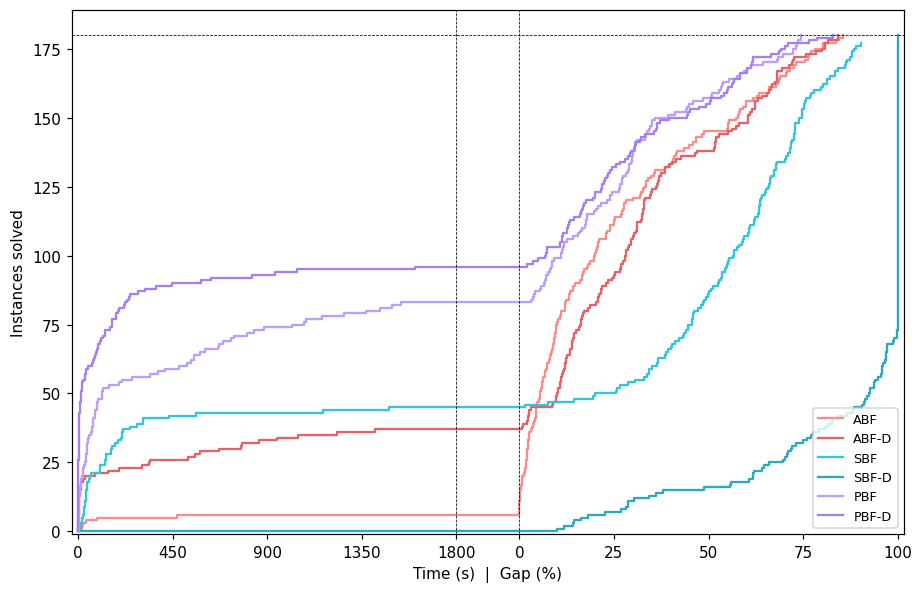

In [25]:
MONO_DEC = select(df, base=['ABF', 'PBF', 'SBF'], extended=False)

performance_profile(df, MONO_DEC, time_scale=TIME_SCALE, figsize=(8.5, 5.5),
                    filename=figure_file('performance_profile_1.png'))

In [13]:
_ = table(MONO_DEC,
          metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Nodes'),
          caption=r'Summary of results for the monolithic formulations and '
                  r'their decompositions. Results for \ref{sbf} exclude the '
                  r'three instances on which the solver terminated with an '
                  r'error.',
          label='tab:mono-dec', column_format='lrrrrr')

,Procedure,#Opt,TimeOpt,Gap (%),Gap (NoOpt) (%),Nodes
0,ABF,6,106.95,24.91,25.77,"197,738"
1,ABF-D,37,296.01,27.82,35.01,"336,128"
2,SBF,45,178.05,43.78,58.71,"484,881"
3,SBF-D,0,-,88.29,88.29,"238,701"
4,PBF,83,306.38,17.19,31.89,"43,710"
5,PBF-D,96,118.02,16.12,34.54,"360,391"


\begin{table}[htbp]
\caption{Summary of results for the monolithic formulations and their decompositions. Results for \ref{sbf} exclude the three instances on which the solver terminated with an error.}
\label{tab:mono-dec}
\begin{tabular}{lrrrrr}
\toprule
Procedure & \#Opt & TimeOpt & Gap (\%) & Gap (NoOpt) (\%) & Nodes \\
\midrule
ABF & 6 & 106.95 & 24.91 & 25.77 & 197{,}738 \\
ABF-D & 37 & 296.01 & 27.82 & 35.01 & 336{,}128 \\
SBF & 45 & 178.05 & 43.78 & 58.71 & 484{,}881 \\
SBF-D & 0 & - & 88.29 & 88.29 & 238{,}701 \\
PBF & 83 & 306.38 & 17.19 & 31.89 & 43{,}710 \\
PBF-D & 96 & 118.02 & 16.12 & 34.54 & 360{,}391 \\
\bottomrule
\end{tabular}
\end{table}



## Exact vs. approximated monolithic

The table carries the mean continuous-relaxation gap merged above.

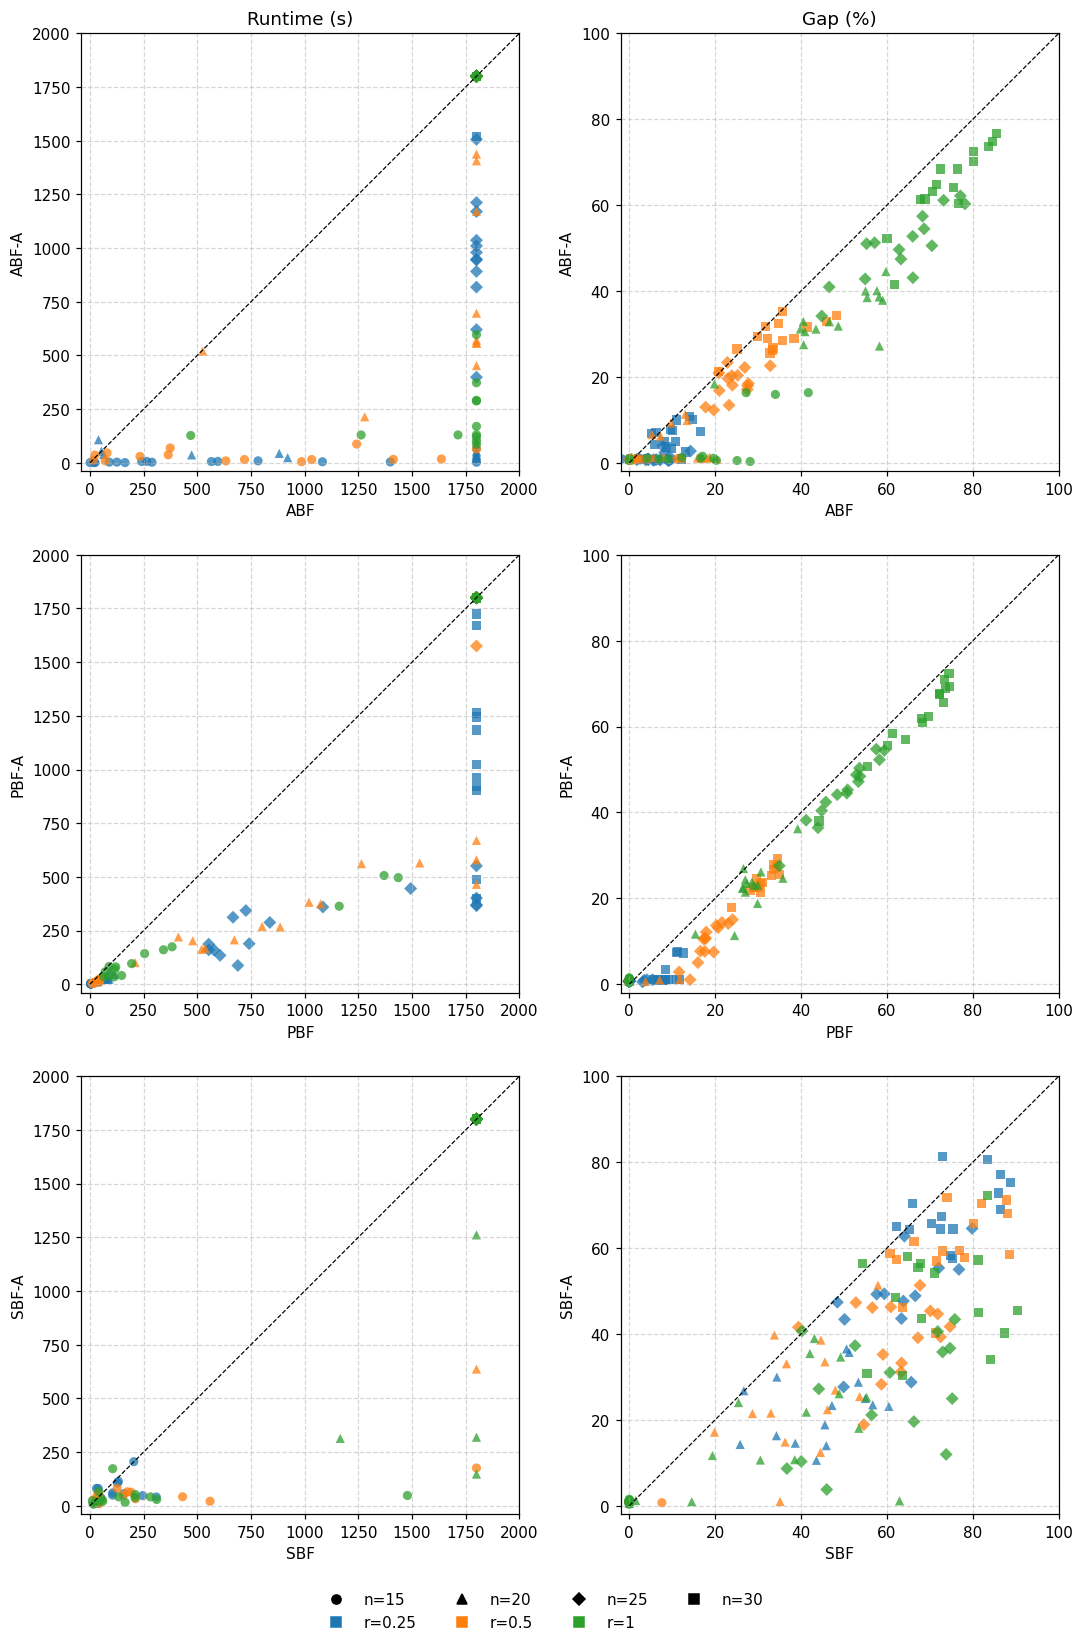

In [14]:
EXACT_APPROX = select(df, base=['ABF', 'PBF', 'SBF'], decomposition=False)
APPROX_PAIRS = [(select(df, base=b, extended=False, decomposition=False)[0],
                 select(df, base=b, extended=True, decomposition=False)[0])
                for b in ('ABF', 'PBF', 'SBF')]

pairwise_scatter(df, pairs=APPROX_PAIRS, metrics=('Time', 'GapPct'),
                 color_by='r_mean', marker_by='n', title='',
                 filename=figure_file('pairwise_scatter_1.png'))

In [15]:
_ = table(EXACT_APPROX,
          metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)',
                   'Root gap (%)', 'Nodes'),
          caption=r'Summary of results for the exact monolithic formulations '
                  r'and their approximations.',
          label='tab:exact-approx', column_format='lrrrrrr')

,Procedure,#Opt,TimeOpt,Gap (%),Gap (NoOpt) (%),Root gap (%),Nodes
0,ABF,6,106.95,24.91,25.77,100.00,"197,738"
1,ABF-A,80,306.10,17.86,31.44,100.00,"276,901"
2,SBF,45,178.05,43.78,58.71,81.91,"484,881"
3,SBF-A,50,99.31,29.88,41.03,82.06,"1,477,916"
4,PBF,83,306.38,17.19,31.89,51.05,"43,710"
5,PBF-A,102,254.23,14.28,31.74,51.71,"21,459"


\begin{table}[htbp]
\caption{Summary of results for the exact monolithic formulations and their approximations.}
\label{tab:exact-approx}
\begin{tabular}{lrrrrrr}
\toprule
Procedure & \#Opt & TimeOpt & Gap (\%) & Gap (NoOpt) (\%) & Root gap (\%) & Nodes \\
\midrule
ABF & 6 & 106.95 & 24.91 & 25.77 & 100.00 & 197{,}738 \\
ABF-A & 80 & 306.10 & 17.86 & 31.44 & 100.00 & 276{,}901 \\
SBF & 45 & 178.05 & 43.78 & 58.71 & 81.91 & 484{,}881 \\
SBF-A & 50 & 99.31 & 29.88 & 41.03 & 82.06 & 1{,}477{,}916 \\
PBF & 83 & 306.38 & 17.19 & 31.89 & 51.05 & 43{,}710 \\
PBF-A & 102 & 254.23 & 14.28 & 31.74 & 51.71 & 21{,}459 \\
\bottomrule
\end{tabular}
\end{table}



## Decompositions with and without approximation

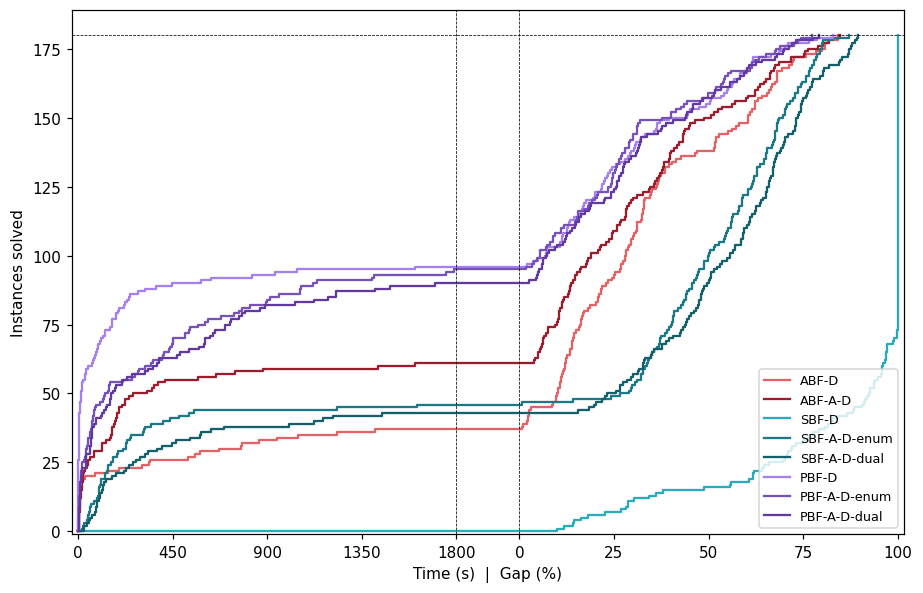

In [26]:
DEC_APPROX = select(df, base=['ABF', 'PBF', 'SBF'], decomposition=True)

performance_profile(df, DEC_APPROX, time_scale=TIME_SCALE, figsize=(8.5, 5.5),
                    filename=figure_file('performance_profile_2.png'))

In [17]:
_ = table(DEC_APPROX,
          metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Cuts',
                   'Nodes'),
          caption=r'Summary of results for the decompositions and their '
                  r'approximated counterparts.',
          label='tab:dec-approx', column_format='lrrrrrr')

,Procedure,#Opt,TimeOpt,Gap (%),Gap (NoOpt) (%),#Cuts,Nodes
0,ABF-D,37,296.01,27.82,35.01,41630.68,"336,128"
1,ABF-A-D,61,198.33,22.87,34.59,137.28,"277,307"
2,SBF-D,0,-,88.29,88.29,5231.48,"238,701"
3,SBF-A-D-enum,46,235.01,40.93,54.98,543.13,"1,301,516"
4,SBF-A-D-dual,43,344.51,43.90,57.68,427.53,"776,271"
5,PBF-D,96,118.02,16.12,34.54,1463.11,"360,391"
6,PBF-A-D-enum,95,330.53,15.44,32.70,172.41,"19,123"
7,PBF-A-D-dual,90,324.73,16.77,33.55,117.04,"17,484"


\begin{table}[htbp]
\caption{Summary of results for the decompositions and their approximated counterparts.}
\label{tab:dec-approx}
\begin{tabular}{lrrrrrr}
\toprule
Procedure & \#Opt & TimeOpt & Gap (\%) & Gap (NoOpt) (\%) & \#Cuts & Nodes \\
\midrule
ABF-D & 37 & 296.01 & 27.82 & 35.01 & 41630.68 & 336{,}128 \\
ABF-A-D & 61 & 198.33 & 22.87 & 34.59 & 137.28 & 277{,}307 \\
SBF-D & 0 & - & 88.29 & 88.29 & 5231.48 & 238{,}701 \\
SBF-A-D-enum & 46 & 235.01 & 40.93 & 54.98 & 543.13 & 1{,}301{,}516 \\
SBF-A-D-dual & 43 & 344.51 & 43.90 & 57.68 & 427.53 & 776{,}271 \\
PBF-D & 96 & 118.02 & 16.12 & 34.54 & 1463.11 & 360{,}391 \\
PBF-A-D-enum & 95 & 330.53 & 15.44 & 32.70 & 172.41 & 19{,}123 \\
PBF-A-D-dual & 90 & 324.73 & 16.77 & 33.55 & 117.04 & 17{,}484 \\
\bottomrule
\end{tabular}
\end{table}



## By instance features

The best decomposition of each formulation, plus PBF-D.

In [18]:
SELECTED = select(df, formulations=['ABF-A-D-S-B', 'PBF-D-dual-S-OC-B',
                                    'PBF-A-D-enum-S-B', 'SBF-A-D-enum-B'])
list(zip(SELECTED, simplify_labels(SELECTED)))

[('ABF-A-D-S-B', 'ABF-A-D'),
 ('SBF-A-D-enum-B', 'SBF-A-D'),
 ('PBF-D-dual-S-OC-B', 'PBF-D'),
 ('PBF-A-D-enum-S-B', 'PBF-A-D')]

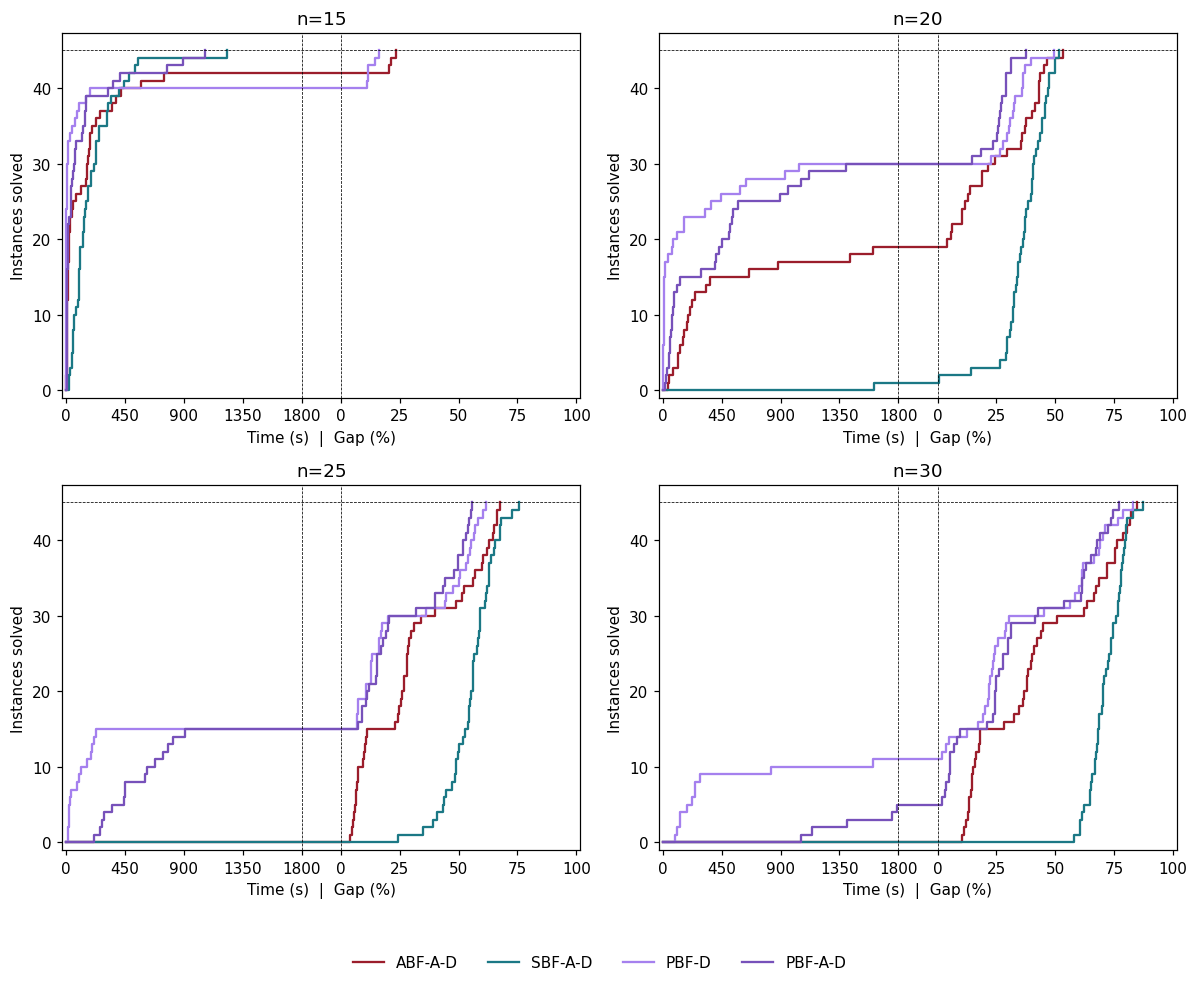

In [19]:
performance_profile(df, SELECTED, time_scale=TIME_SCALE, facet_by='n',
                    ncols=2,
                    filename=figure_file('performance_profile_4.png'))

In [20]:
_ = table(SELECTED, by='n',
          metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Cuts',
                   'Nodes'),
          caption=r'Summary of results for the selected decompositions '
                  r'grouped by number of locations.',
          label='tab:by-n', column_format='llrrrrrr')

,n,Procedure,#Opt,TimeOpt,Gap (%),Gap (NoOpt) (%),#Cuts,Nodes
0,15,ABF-A-D,42,117.59,1.45,21.82,171.93,"203,143"
1,20,ABF-A-D,19,376.80,16.32,28.24,137.13,"417,329"
2,25,ABF-A-D,0,-,31.28,31.28,128.93,"306,096"
3,30,ABF-A-D,0,-,42.43,42.43,111.11,"182,660"
4,15,SBF-A-D,45,204.39,0.00,-,946.16,"444,759"
5,20,SBF-A-D,1,1612.95,36.43,37.26,690.96,"2,195,628"
6,25,SBF-A-D,0,-,55.44,55.44,275.29,"1,534,943"
7,30,SBF-A-D,0,-,71.84,71.84,260.11,"1,030,735"
8,15,PBF-D,40,18.64,1.44,12.99,800.58,"72,979"
9,20,PBF-D,30,168.66,11.10,33.31,1470.93,"340,889"


\begin{table}[htbp]
\caption{Summary of results for the selected decompositions grouped by number of locations.}
\label{tab:by-n}
\begin{tabular}{llrrrrrr}
\toprule
$n$ & Procedure & \#Opt & TimeOpt & Gap (\%) & Gap (NoOpt) (\%) & \#Cuts & Nodes \\
\midrule
15 & ABF-A-D & 42 & 117.59 & 1.45 & 21.82 & 171.93 & 203{,}143 \\
20 & ABF-A-D & 19 & 376.80 & 16.32 & 28.24 & 137.13 & 417{,}329 \\
25 & ABF-A-D & 0 & - & 31.28 & 31.28 & 128.93 & 306{,}096 \\
30 & ABF-A-D & 0 & - & 42.43 & 42.43 & 111.11 & 182{,}660 \\
15 & SBF-A-D & 45 & 204.39 & 0.00 & - & 946.16 & 444{,}759 \\
20 & SBF-A-D & 1 & 1612.95 & 36.43 & 37.26 & 690.96 & 2{,}195{,}628 \\
25 & SBF-A-D & 0 & - & 55.44 & 55.44 & 275.29 & 1{,}534{,}943 \\
30 & SBF-A-D & 0 & - & 71.84 & 71.84 & 260.11 & 1{,}030{,}735 \\
15 & PBF-D & 40 & 18.64 & 1.44 & 12.99 & 800.58 & 72{,}979 \\
20 & PBF-D & 30 & 168.66 & 11.10 & 33.31 & 1470.93 & 340{,}889 \\
25 & PBF-D & 15 & 97.20 & 21.62 & 32.42 & 1984.71 & 470{,}155 \\
30 & PBF-D & 11 & 369.65 & 30.3

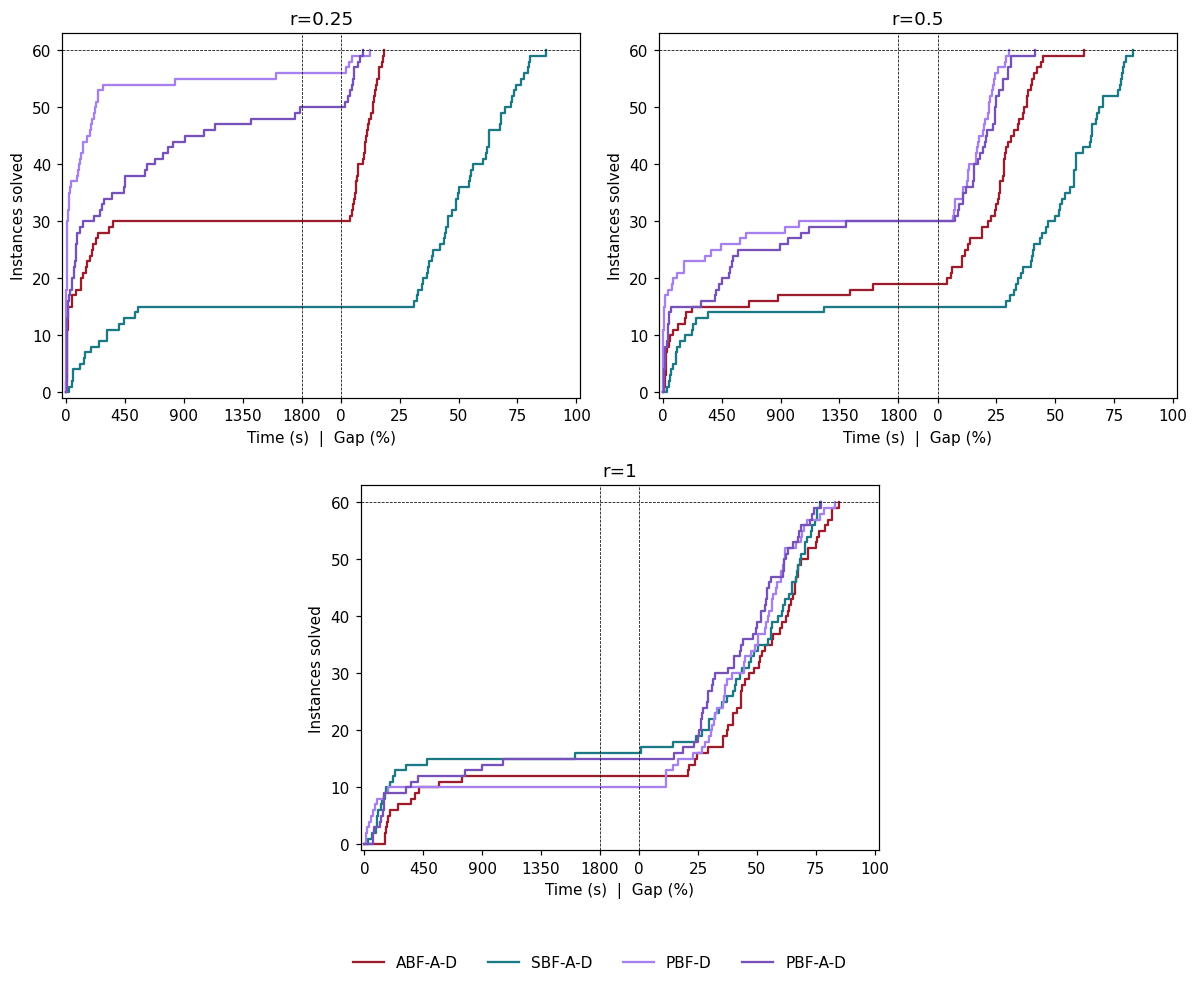

In [21]:
performance_profile(df, SELECTED, time_scale=TIME_SCALE, facet_by='r_mean',
                    ncols=2,
                    filename=figure_file('performance_profile_3.png'))

In [22]:
_ = table(SELECTED, by='r_mean',
          metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Cuts',
                   'Nodes'),
          caption=r'Summary of results for the selected decompositions '
                  r'grouped by radius values.',
          label='tab:by-r', column_format='llrrrrrr')

,r,Procedure,#Opt,TimeOpt,Gap (%),Gap (NoOpt) (%),#Cuts,Nodes
0,0.25,ABF-A-D,30,90.65,5.50,11.01,84.50,"143,358"
1,0.50,ABF-A-D,19,295.52,19.08,27.93,102.95,"277,988"
2,1.00,ABF-A-D,12,313.65,44.02,55.03,224.38,"410,576"
3,0.25,SBF-A-D,15,236.14,41.77,55.69,355.23,"1,358,840"
4,0.50,SBF-A-D,15,210.62,42.30,56.40,424.63,"1,256,492"
5,1.00,SBF-A-D,16,256.81,38.71,52.79,849.52,"1,289,217"
6,0.25,PBF-D,56,99.96,0.38,5.75,376.70,"100,898"
7,0.50,PBF-D,30,167.85,9.02,18.03,1101.15,"414,247"
8,1.00,PBF-D,10,69.62,38.95,46.74,2911.47,"566,027"
9,0.25,PBF-A-D,50,321.79,0.91,5.43,106.25,"7,992"


\begin{table}[htbp]
\caption{Summary of results for the selected decompositions grouped by radius values.}
\label{tab:by-r}
\begin{tabular}{llrrrrrr}
\toprule
$r$ & Procedure & \#Opt & TimeOpt & Gap (\%) & Gap (NoOpt) (\%) & \#Cuts & Nodes \\
\midrule
0.25 & ABF-A-D & 30 & 90.65 & 5.50 & 11.01 & 84.50 & 143{,}358 \\
0.50 & ABF-A-D & 19 & 295.52 & 19.08 & 27.93 & 102.95 & 277{,}988 \\
1.00 & ABF-A-D & 12 & 313.65 & 44.02 & 55.03 & 224.38 & 410{,}576 \\
0.25 & SBF-A-D & 15 & 236.14 & 41.77 & 55.69 & 355.23 & 1{,}358{,}840 \\
0.50 & SBF-A-D & 15 & 210.62 & 42.30 & 56.40 & 424.63 & 1{,}256{,}492 \\
1.00 & SBF-A-D & 16 & 256.81 & 38.71 & 52.79 & 849.52 & 1{,}289{,}217 \\
0.25 & PBF-D & 56 & 99.96 & 0.38 & 5.75 & 376.70 & 100{,}898 \\
0.50 & PBF-D & 30 & 167.85 & 9.02 & 18.03 & 1101.15 & 414{,}247 \\
1.00 & PBF-D & 10 & 69.62 & 38.95 & 46.74 & 2911.47 & 566{,}027 \\
0.25 & PBF-A-D & 50 & 321.79 & 0.91 & 5.43 & 106.25 & 7{,}992 \\
0.50 & PBF-A-D & 30 & 348.66 & 10.46 & 20.91 & 135.78 & 16{,}1

## Against Behdani and Smith

Completing the B&S iterations and solving to optimality are different
events, so they are separate columns; `Time` averages over each procedure's
own terminated runs.

In [23]:
BS, PBF_D = 'BS-B', 'PBF-D-dual-S-OC-B'

bs = head_to_head(df, BS, PBF_D, by='n', time='completed')
bs = bs[['n', 'BS solved', 'Time BS', 'Gap BS',
         'PBF-D solved', 'Time PBF-D', 'Gap PBF-D']]
bs.columns = pd.MultiIndex.from_tuples([
    ('', '$n$'),
    ('BS', r'\#Completed'), ('BS', 'Time'), ('BS', r'Gap (\%)'),
    ('PBF-D', r'\#Opt'), ('PBF-D', 'Time'), ('PBF-D', r'Gap (\%)')])
for column in bs.columns[1:]:
    fmt = '{:.0f}' if ('Completed' in column[1] or 'Opt' in column[1]) else '{:.2f}'
    bs[column] = ['-' if pd.isna(v) else fmt.format(v) for v in bs[column]]

display(bs)
if PRINT_LATEX:
    latex = bs.to_latex(index=False, escape=False, multicolumn_format='c',
                        caption=r'Summary of results for BS and \ref{pbf-d} '
                                r'by $n$.',
                        label='tab:bs-pbf', position='tbp',
                        column_format='rrrrrrr')
    # to_latex emits the \multicolumn row but no rules beneath it
    head = r'\multicolumn{3}{c}{PBF-D} \\'
    latex = latex.replace(head, head + '\n'
                          r'\cmidrule(lr){2-4} \cmidrule(lr){5-7}')
    print(latex)

BS                  PBF-D                 
  $n$ \#Completed    Time Gap (\%) \#Opt    Time Gap (\%)
0  15          30   90.86    10.75    40   18.64     1.44
1  20          15  225.80    24.10    30  168.66    11.10
2  25           0       -    35.31    15   97.20    21.62
3  30           0       -    41.00    11  369.65    30.30

\begin{table}[tbp]
\caption{Summary of results for BS and \ref{pbf-d} by $n$.}
\label{tab:bs-pbf}
\begin{tabular}{rrrrrrr}
\toprule
 & \multicolumn{3}{c}{BS} & \multicolumn{3}{c}{PBF-D} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7}
$n$ & \#Completed & Time & Gap (\%) & \#Opt & Time & Gap (\%) \\
\midrule
15 & 30 & 90.86 & 10.75 & 40 & 18.64 & 1.44 \\
20 & 15 & 225.80 & 24.10 & 30 & 168.66 & 11.10 \\
25 & 0 & - & 35.31 & 15 & 97.20 & 21.62 \\
30 & 0 & - & 41.00 & 11 & 369.65 & 30.30 \\
\bottomrule
\end{tabular}
\end{table}



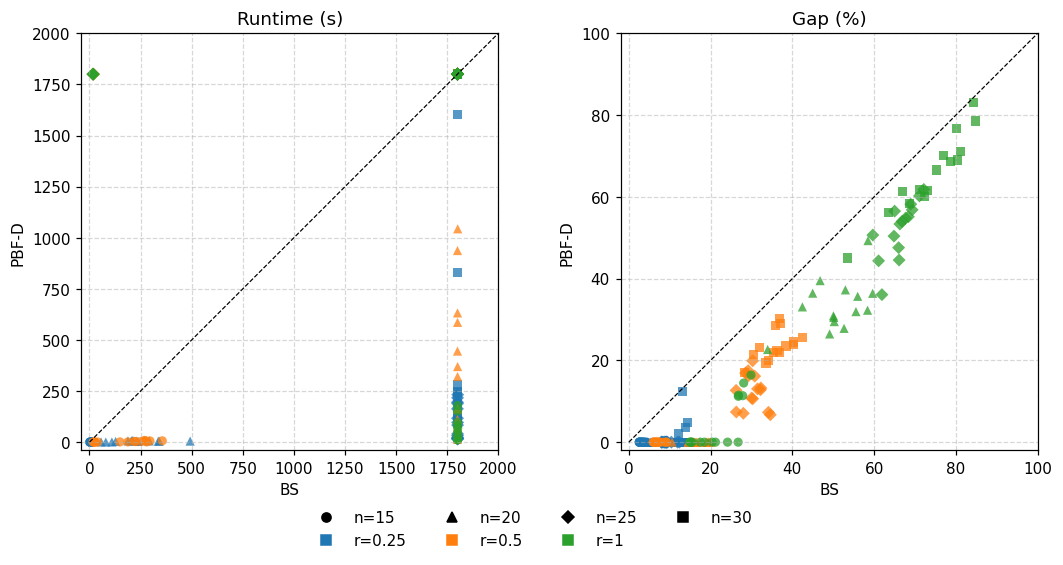

In [24]:
pairwise_scatter(df, BS, PBF_D, metrics=('Time', 'GapPct'),
                 color_by='r_mean', marker_by='n', title='',
                 filename=figure_file('pairwise_scatter_2.png'))